Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model and tokenizer loaded successfully!
Sales of electronics and home goods and accessories have soared in the coming quarter, with the electronics department gaining a record high.



Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 loaded successfully!
The Smart Home Security Camera provides  an integrated microphone that can be used to record and record video. It can be a simple device for recording and recording an audio signal, or it can be a simple camera capable of recording sound and can be very useful in the home.  This camera is a pretty good camera for capturing sounds,

The Multifunction Air Fryer Oven combines n a small, sturdy, stainless steel utensil with a stainless steel lid. In addition to its sturdy packaging, the oven vacuuming kit also comes with a small, stainless steel screw to allow for easy removal if you need to. The oven vacuuming kit is constructed of stainless steel

Running on: cpu


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


... (4 outputs left out)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Image-generation model loaded!


  0%|          | 0/25 [00:00<?, ?it/s]

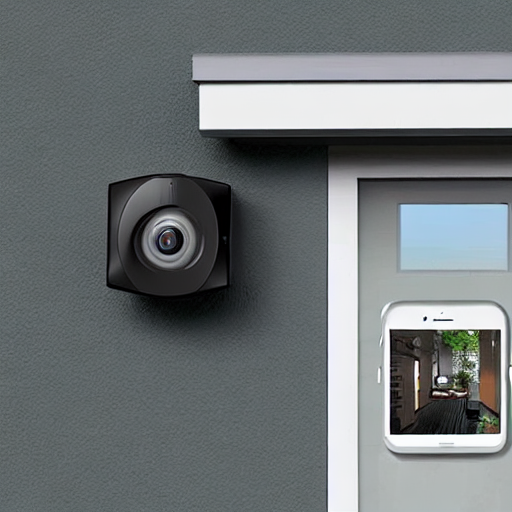

  0%|          | 0/25 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
#-----------------------------------------------
# FLAN - T5
#-----------------------------------------------

#Cell 1 — Install the library

!pip -q install transformers sentencepiece

#Cell 2 — Load the model

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

# Load the model and tokenizer directly for seq2seq task
model_name = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model and tokenizer loaded successfully!")

#Cell 3 — Give it a useful task

# A sample business report
report = """
Sales performance for the month of September showed steady
growth across all product categories. Total sales revenue reached $125,000,
representing a 12% increase compared to August. The electronics department generated the highest revenue,
accounting for 45% of total sales, while home goods and accessories also experienced moderate growth.
Customer demand was strongest during weekend promotions, which contributed significantly to overall results.

Looking ahead, the sales team plans to continue targeted marketing campaigns and
seasonal promotions to maintain momentum. Inventory levels remain sufficient
to meet expected demand, and customer satisfaction ratings have stayed above 90%.
Based on current trends, the company projects continued sales growth in the
coming quarter, particularly in high-demand product segments.
"""

# Tell the model what to do
prompt = "Summarize this business report " + report

# Tokenize inputs
inputs = tokenizer(prompt, return_tensors="pt")

# Generate the summary
outputs = model.generate(
    **inputs,
    max_new_tokens=500,
    do_sample=False
)

# Decode and print the result
result = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(result)
print()

#-----------------------------------------------
# GPT - 2
#-----------------------------------------------

#Cell 1 — Load the model

from transformers import pipeline

# Load a pretrained text-generation model
generator = pipeline(
    "text-generation",
    model="openai-community/gpt2"
)

print("GPT-2 loaded successfully!")

#Cell 2 — Generate content

# Start with a product description prompt
prompt = "The Smart Home Security Camera provides "

# Ask GPT-2 to continue the text
result = generator(
    prompt,
    max_new_tokens=60,
    do_sample=True,
    temperature=0.8,
    top_k=50,
    num_return_sequences=1,
    pad_token_id=generator.tokenizer.eos_token_id
)

print(result[0]["generated_text"])
print()

#Cell 3 — Experiment with a different prompt

prompt = "The Multifunction Air Fryer Oven combines "

result = generator(
    prompt,
    max_new_tokens=60,
    do_sample=True,
    temperature=0.8,
    pad_token_id=generator.tokenizer.eos_token_id
)

print(result[0]["generated_text"])
print()

#-----------------------------------------------
# Stable Diffusion
#-----------------------------------------------

#Cell 1 — Install the required libraries

!pip -q install diffusers transformers accelerate safetensors

#Cell 2 — Load the image-generation model

import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Use a GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# Load a pretrained text-to-image model
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

image_generator = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

image_generator = image_generator.to(device)

print("Image-generation model loaded!")

#Cell 3 — Generate a business-related image

prompt = """
A compact smart security camera that provides high-definition video,
motion detection, and mobile alerts. Its simple design and easy setup
make it a popular choice for modern homeowners.
"""

# Generate the image
result = image_generator(
    prompt=prompt,
    num_inference_steps=25,
    guidance_scale=7.5
)

# Display the generated image
generated_image = result.images[0]
display(generated_image)

#Cell 4 — Try a different prompt

prompt = """
A versatile air fryer oven designed for fast, convenient cooking. With
multiple cooking modes and a sleek design, it helps users prepare meals
efficiently while saving counter space.
"""

result = image_generator(
    prompt=prompt,
    num_inference_steps=25,
    guidance_scale=7.5
)

display(result.images[0])


PART A:


Summary: Sales of electronics and home goods and accessories have soared in the coming quarter, with the electronics department gaining a record high.

Analyzation: The generated summary gets the key idea behind the report, but fails to provide important details like any numbers or accounting for the future plans in the second paragraph. Even increasing the possible new tokens does not help make hte generated summary better.


PART B:

Product One: The Smart Home Security Camera provides 【4.2" or more】 resolution, but it can also be mounted at the front of the unit, or you can mount it on the rear of the unit.

Product Two: The Multifunction Air Fryer Oven combines iced coffee with the flavor of high-energy organic coffee with a balanced and light flavors of coffee. The Multifunction Air Fryer Oven, available in 6 different flavors, can be rotated or combined to make a full-sized oven to serve as a personal, on-the-go,

Analyzation: Changing the tokens allowed made the model give more information on the products, yet no matter how the temperature or amount was modified, each of the outputs failed to give a plausible product description that could be used in the real world. Overall the security camera gave a description that was more related so it would be slightly better than the air fryer, but still not particularly useful.


PART C:


Images: Generated in code

Analyzation: The images are fairly generic, but still represent the products well, making sure the products appear professional and high quality.


PART D:


Useful Output: The text generated by the first two models was barely actually related to the business prompts and ideas where the images might be able to be used in an advertisment. Therefore the most useful or real world applicable result is the two generated images.

Different Prompts Impact: The two different prompts for image and product description generation created varied outputs. For instance, the security camera product generated more consistently relevant results, most likely because it is a more specific product.

Possible Limitations: The generated text was limited by a very unspecific prompt and little additional context. With any predictive model like this, a lot of direction is needed for a satisfying result to be achieved.

Human Review: I doubt any of these generations would be able to be used in a real business scenario. They might be fine to build some general ideas as a foundation, but they only provide a framework, not a finished product. An actual person would be needed to refine everything.
